# 01. 記述統計・可視化

処置変数（MW）とアウトカム変数の記述統計。分析サンプル（2019年除外）を使用。

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

plt.style.use('seaborn-v0_8-whitegrid')
import japanize_matplotlib  # style.use の後に import

OUT = Path('../output/figures')
OUT.mkdir(parents=True, exist_ok=True)

df = pd.read_csv('../data/analysis_sample.csv')
print(f'Shape: {df.shape}')

Shape: (6909, 21)


## 1. Summary Statistics

In [2]:
desc_cols = {
    'min_wage': '最低賃金（円/時）',
    'log_mw': 'log(最低賃金)',
    'wage_total': '現金給与総額（円）',
    'wage_scheduled': '所定内給与（円）',
    'wage_overtime': '超過労働給与（円）',
    'hours_total': '総実労働時間（時間）',
    'hours_scheduled': '所定内労働時間（時間）',
    'hours_overtime': '所定外労働時間（時間）',
    'workers': '常用労働者数',
    'days_worked': '出勤日数（日）',
}

stats = df[list(desc_cols.keys())].describe().T
stats.index = [desc_cols[c] for c in stats.index]
stats = stats[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
print(stats.round(1).to_string())

              count      mean      std       min       25%       50%       75%       max
最低賃金（円/時）    6909.0     831.5    115.0     652.0     737.0     821.0     908.0    1226.0
log(最低賃金)    6909.0       6.7      0.1       6.5       6.6       6.7       6.8       7.1
現金給与総額（円）    6909.0  297370.6  86825.5  203638.0  246920.0  261436.0  305494.0  800301.0
所定内給与（円）     6909.0  230031.1  18809.2  188265.0  219012.0  228487.0  236656.0  350096.0
超過労働給与（円）    6909.0   17711.8   3047.8    9534.0   15521.0   17568.0   19666.0   27638.0
総実労働時間（時間）   6909.0     142.7      8.3     109.0     137.0     143.0     148.8     166.0
所定内労働時間（時間）  6909.0     132.7      7.8     102.9     127.4     132.9     138.3     155.2
所定外労働時間（時間）  6909.0      10.0      1.4       5.2       9.0      10.0      10.9      15.8
常用労働者数       6909.0    1000.4   1291.3      70.2     372.8     528.8     984.8    8777.0
出勤日数（日）      6909.0      18.6      1.0      14.9      17.9      18.7      19.4      21.2


## 2. 処置変数（最低賃金）の記述

In [3]:
# 都道府県グループ定義
mw_2024oct = df[(df['year'] == 2024) & (df['month'] == 10)].set_index('pref_name')['min_wage']
high_mw = ['東京', '神奈川', '大阪', '愛知', '埼玉']
low_mw = ['沖縄', '高知', '秋田', '鳥取', '宮崎']
mid_mw = ['北海道', '福岡', '広島', '宮城', '新潟']

print('2024年10月時点のMW:')
for label, grp in [('高MW', high_mw), ('中MW', mid_mw), ('低MW', low_mw)]:
    vals = mw_2024oct.reindex(grp).dropna()
    print(f'  {label}: {vals.to_dict()}')

2024年10月時点のMW:
  高MW: {'東京': 1163.0, '神奈川': 1162.0, '大阪': 1114.0, '愛知': 1077.0, '埼玉': 1078.0}
  中MW: {'北海道': 1010.0, '福岡': 992.0, '広島': 1020.0, '宮城': 973.0, '新潟': 985.0}
  低MW: {'沖縄': 952.0, '高知': 952.0, '秋田': 951.0, '鳥取': 957.0, '宮崎': 952.0}


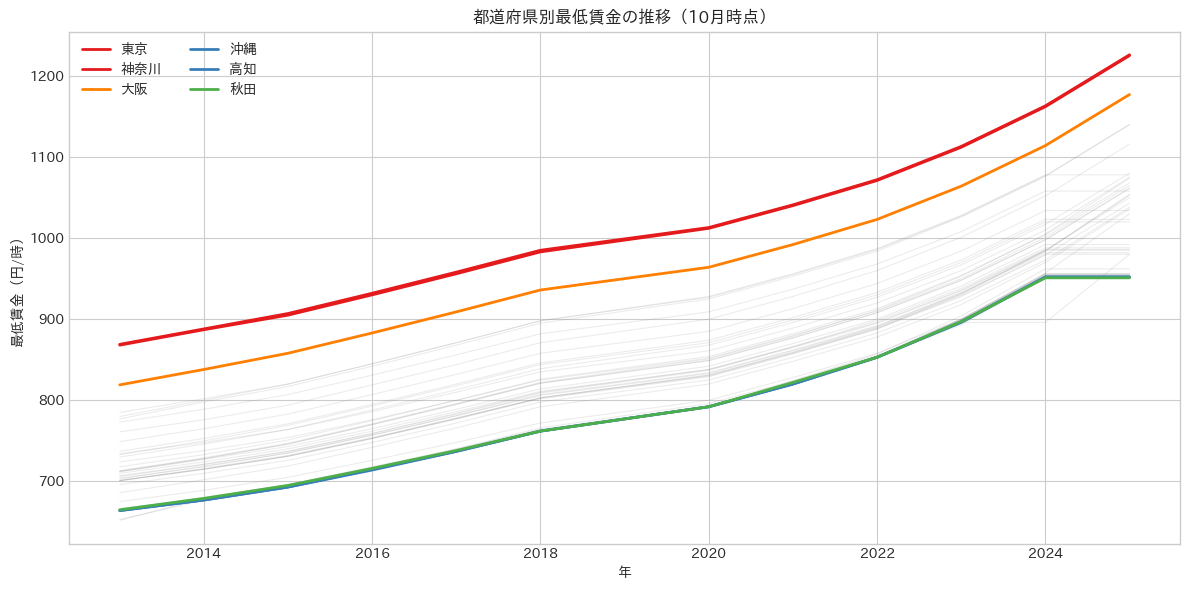

In [4]:
fig, ax = plt.subplots(figsize=(12, 6))

# 全都道府県を薄く
oct_data = df[df['month'] == 10].copy()
for pref in df['pref_code'].unique():
    sub = oct_data[oct_data['pref_code'] == pref]
    ax.plot(sub['year'], sub['min_wage'], color='gray', alpha=0.15, linewidth=0.8)

# グループ別にハイライト
colors = {'東京': '#e41a1c', '神奈川': '#e41a1c', '大阪': '#ff7f00',
          '沖縄': '#377eb8', '高知': '#377eb8', '秋田': '#4daf4a'}
for pref, color in colors.items():
    sub = oct_data[oct_data['pref_name'] == pref]
    ax.plot(sub['year'], sub['min_wage'], color=color, linewidth=2, label=pref)

ax.set_xlabel('年')
ax.set_ylabel('最低賃金（円/時）')
ax.set_title('都道府県別最低賃金の推移（10月時点）')
ax.legend(loc='upper left', ncol=2)
plt.tight_layout()
plt.savefig(OUT / '01_mw_timeseries.png', dpi=150, bbox_inches='tight')
plt.show()

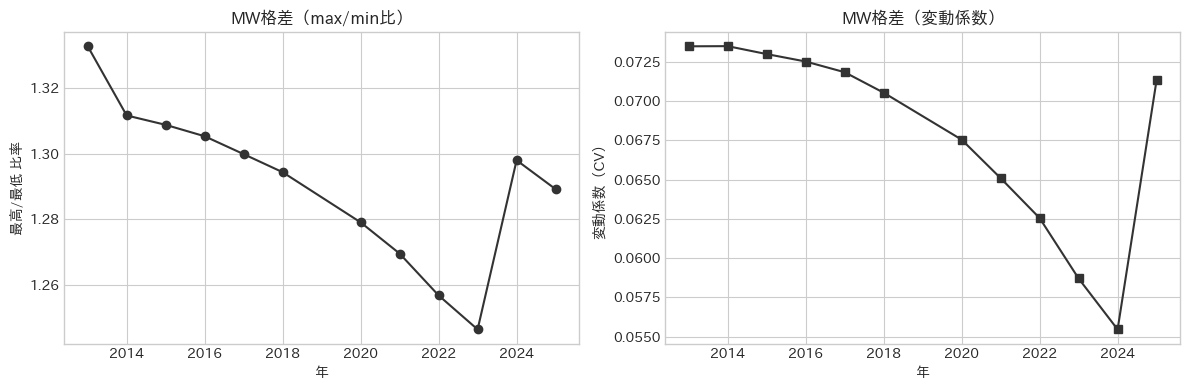

      max_min_ratio     cv
year                      
2013          1.333  0.074
2014          1.312  0.074
2015          1.309  0.073
2016          1.305  0.073
2017          1.300  0.072
2018          1.294  0.071
2020          1.279  0.068
2021          1.270  0.065
2022          1.257  0.063
2023          1.246  0.059
2024          1.298  0.055
2025          1.289  0.071


In [5]:
# MW格差の推移
oct_stats = oct_data.groupby('year')['min_wage'].agg(['min', 'max', 'mean', 'std'])
oct_stats['max_min_ratio'] = oct_stats['max'] / oct_stats['min']
oct_stats['cv'] = oct_stats['std'] / oct_stats['mean']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(oct_stats.index, oct_stats['max_min_ratio'], 'o-', color='#333')
axes[0].set_ylabel('最高/最低 比率')
axes[0].set_title('MW格差（max/min比）')
axes[0].set_xlabel('年')

axes[1].plot(oct_stats.index, oct_stats['cv'], 's-', color='#333')
axes[1].set_ylabel('変動係数（CV）')
axes[1].set_title('MW格差（変動係数）')
axes[1].set_xlabel('年')

plt.tight_layout()
plt.savefig(OUT / '01_mw_dispersion.png', dpi=150, bbox_inches='tight')
plt.show()

print(oct_stats[['max_min_ratio', 'cv']].round(3).to_string())

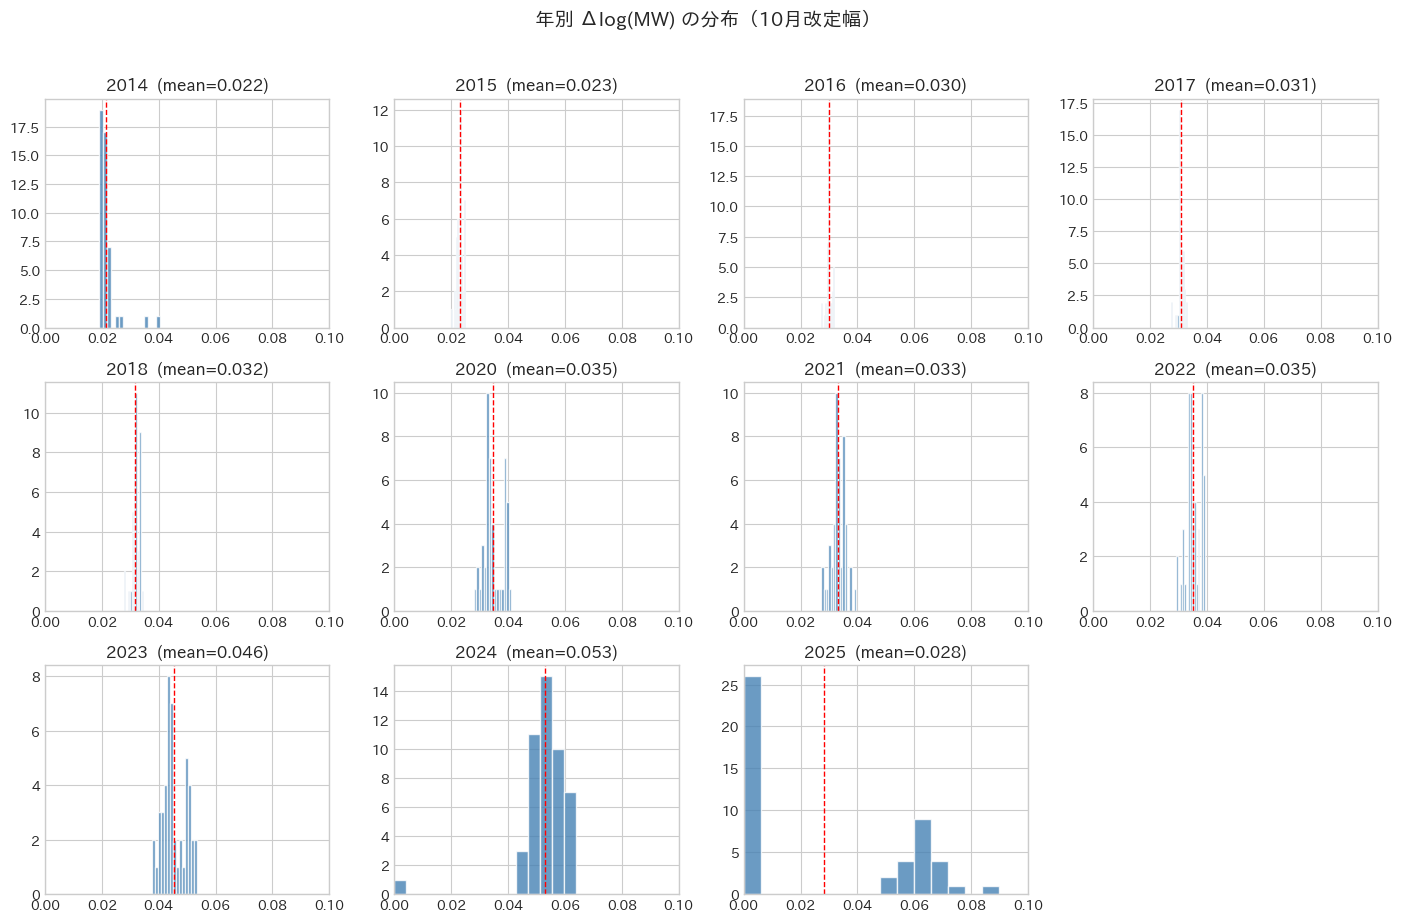

In [6]:
# 年別 Δlog(MW) の分布（処置強度 = dose）
oct_sorted = oct_data.sort_values(['pref_code', 'year'])
oct_sorted['dlog_mw'] = oct_sorted.groupby('pref_code')['log_mw'].diff()
dose = oct_sorted.dropna(subset=['dlog_mw'])

years = sorted(dose['year'].unique())
fig, axes = plt.subplots(3, 4, figsize=(14, 9))
for ax, yr in zip(axes.flat, years):
    sub = dose[dose['year'] == yr]['dlog_mw']
    ax.hist(sub, bins=15, color='steelblue', edgecolor='white', alpha=0.8)
    ax.set_title(f'{yr}  (mean={sub.mean():.3f})')
    ax.set_xlim(0, 0.10)
    ax.axvline(sub.mean(), color='red', linestyle='--', linewidth=1)

for ax in axes.flat[len(years):]:
    ax.set_visible(False)

fig.suptitle('年別 Δlog(MW) の分布（10月改定幅）', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(OUT / '01_dose_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. アウトカム変数の記述

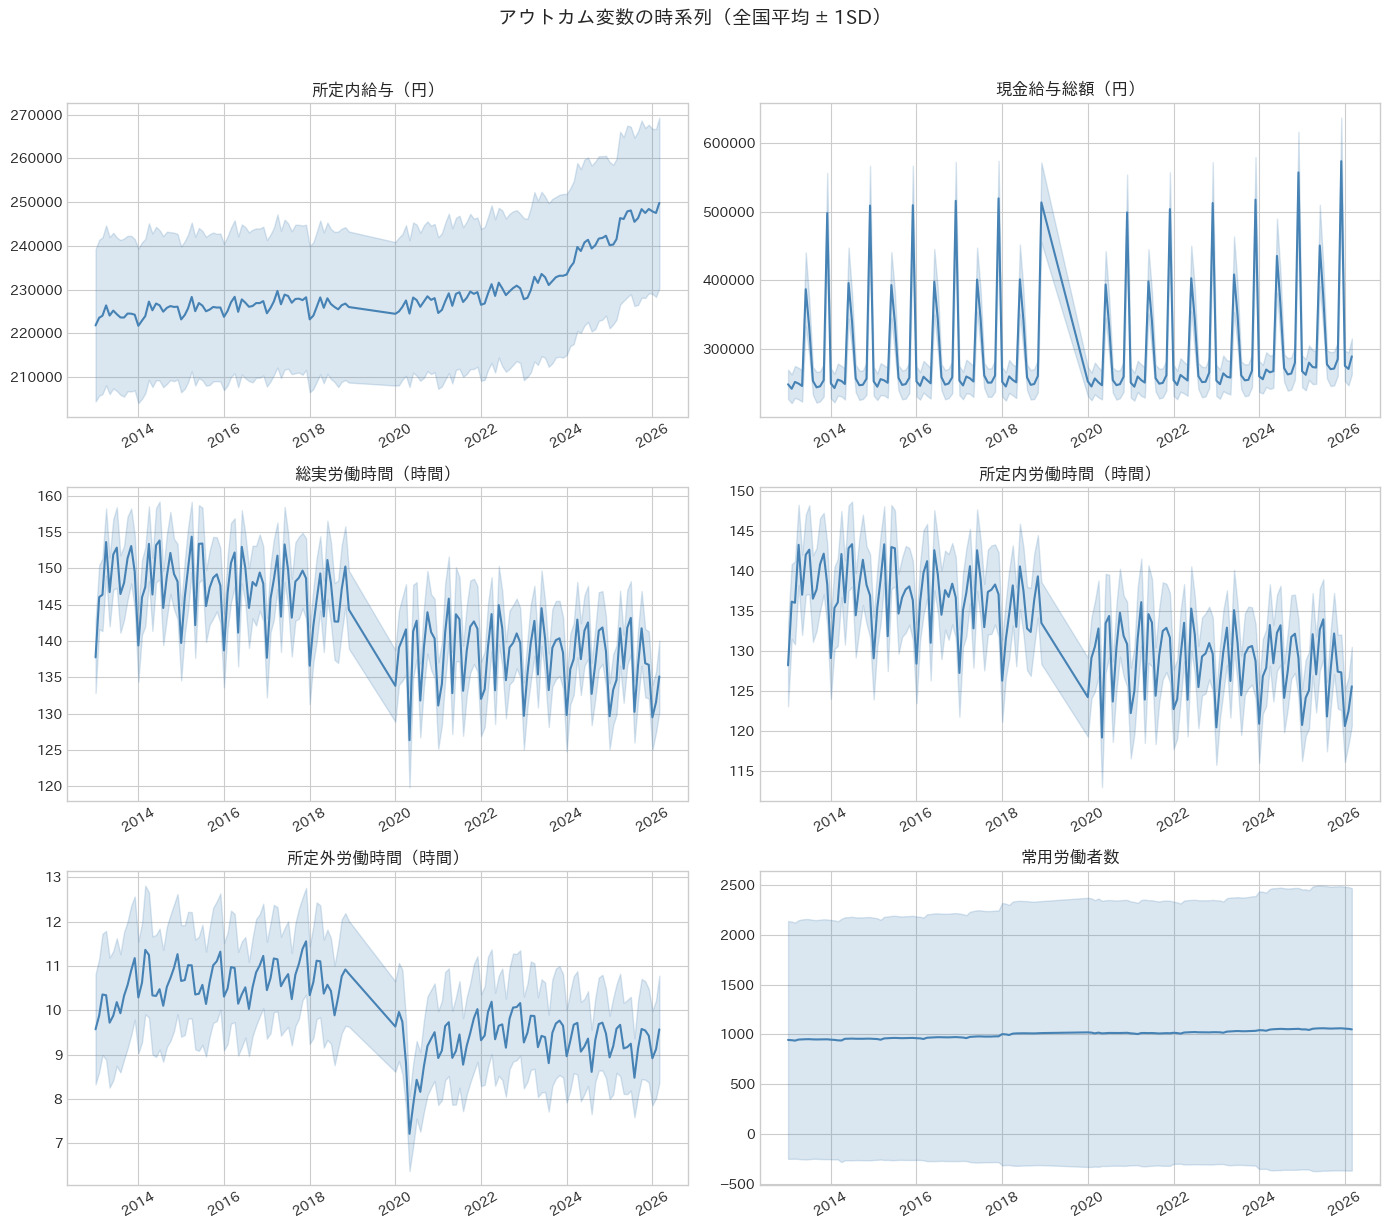

In [7]:
# 主要アウトカムの時系列（全国平均 ± 1SD）
df['yearmonth'] = pd.to_datetime(df['year'].astype(str) + '-' + df['month'].astype(str).str.zfill(2))

outcomes = {
    'wage_scheduled': '所定内給与（円）',
    'wage_total': '現金給与総額（円）',
    'hours_total': '総実労働時間（時間）',
    'hours_scheduled': '所定内労働時間（時間）',
    'hours_overtime': '所定外労働時間（時間）',
    'workers': '常用労働者数',
}

fig, axes = plt.subplots(3, 2, figsize=(14, 12))
for ax, (col, label) in zip(axes.flat, outcomes.items()):
    ts = df.groupby('yearmonth')[col].agg(['mean', 'std'])
    ax.fill_between(ts.index, ts['mean'] - ts['std'], ts['mean'] + ts['std'],
                    alpha=0.2, color='steelblue')
    ax.plot(ts.index, ts['mean'], color='steelblue', linewidth=1.5)
    ax.set_title(label)
    ax.tick_params(axis='x', rotation=30)

plt.suptitle('アウトカム変数の時系列（全国平均 ± 1SD）', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(OUT / '01_outcome_timeseries.png', dpi=150, bbox_inches='tight')
plt.show()

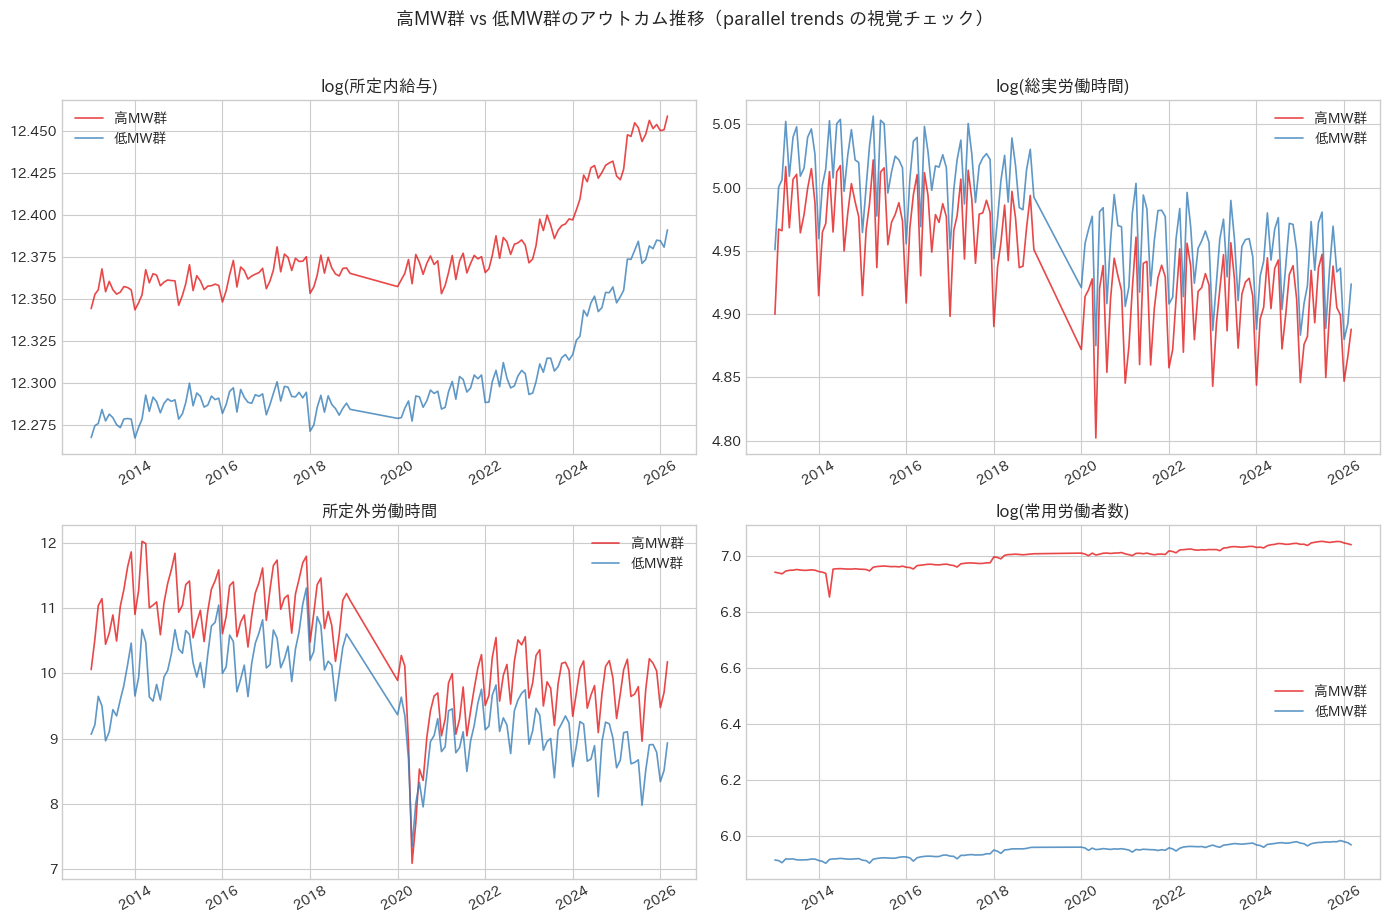

In [8]:
# 高MW群 vs 低MW群のアウトカム比較（parallel trends の視覚チェック）
# 2013年10月時点のMW水準で2グループに分割
mw_2013 = df[(df['year'] == 2013) & (df['month'] == 10)][['pref_code', 'min_wage']]
median_mw = mw_2013['min_wage'].median()
high_prefs = set(mw_2013[mw_2013['min_wage'] >= median_mw]['pref_code'])

df['mw_group'] = df['pref_code'].apply(lambda x: '高MW群' if x in high_prefs else '低MW群')

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
plot_outcomes = ['log_wage_scheduled', 'log_hours_total', 'hours_overtime', 'log_workers']
plot_labels = ['log(所定内給与)', 'log(総実労働時間)', '所定外労働時間', 'log(常用労働者数)']

for ax, col, label in zip(axes.flat, plot_outcomes, plot_labels):
    for grp, color in [('高MW群', '#e41a1c'), ('低MW群', '#377eb8')]:
        ts = df[df['mw_group'] == grp].groupby('yearmonth')[col].mean()
        ax.plot(ts.index, ts, color=color, linewidth=1.2, label=grp, alpha=0.8)
    ax.set_title(label)
    ax.legend()
    ax.tick_params(axis='x', rotation=30)

plt.suptitle('高MW群 vs 低MW群のアウトカム推移（parallel trends の視覚チェック）',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(OUT / '01_parallel_trends_visual.png', dpi=150, bbox_inches='tight')
plt.show()

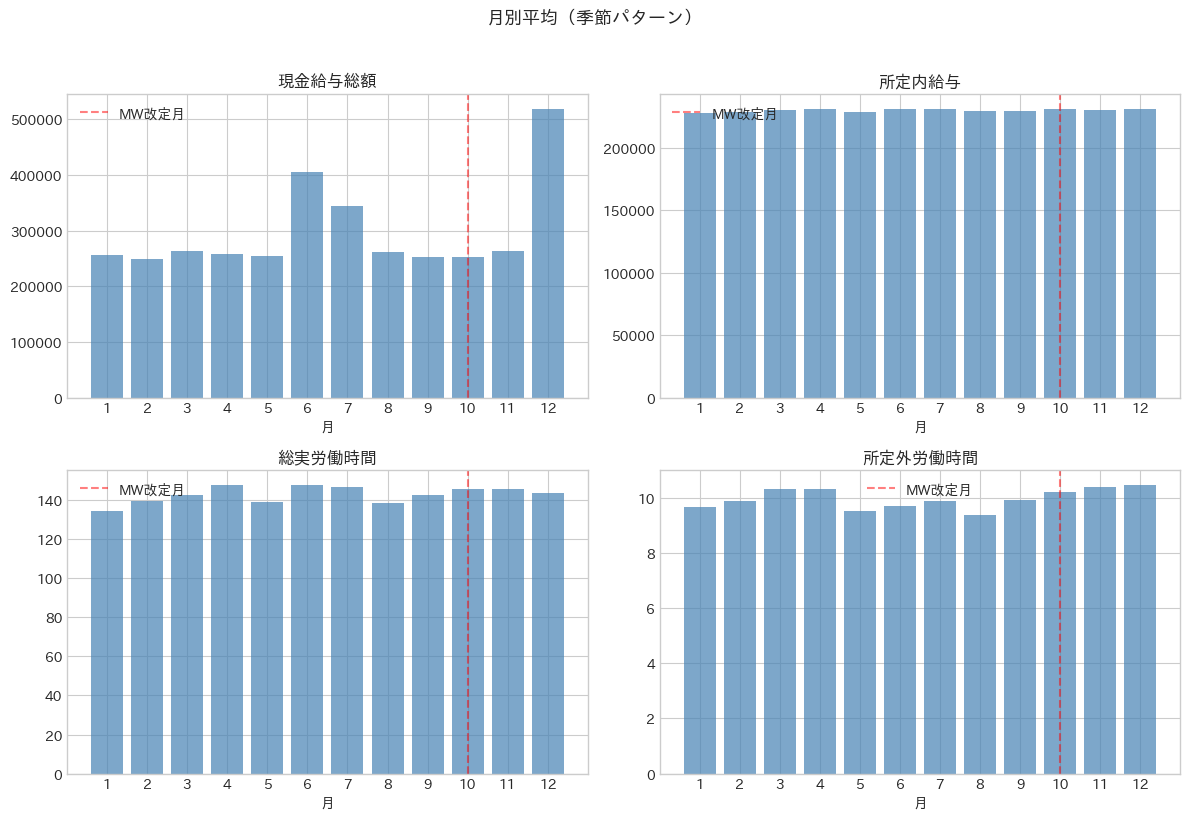

In [9]:
# 季節パターンの確認
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col, label in zip(axes.flat,
    ['wage_total', 'wage_scheduled', 'hours_total', 'hours_overtime'],
    ['現金給与総額', '所定内給与', '総実労働時間', '所定外労働時間']):
    seasonal = df.groupby('month')[col].mean()
    ax.bar(seasonal.index, seasonal.values, color='steelblue', alpha=0.7)
    ax.set_title(label)
    ax.set_xlabel('月')
    ax.set_xticks(range(1, 13))
    ax.axvline(10, color='red', linestyle='--', alpha=0.5, label='MW改定月')
    ax.legend()

plt.suptitle('月別平均（季節パターン）', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(OUT / '01_seasonality.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. 処置 × アウトカムの予備的関係

In [10]:
# 年次パネル作成（10月〜翌9月のMW年度で集約）
# MW年度: 10月改定の年をその年度とする
# e.g., 2022年10月〜2023年9月 → mw_year = 2022
df_copy = df.copy()
df_copy['mw_year'] = np.where(df_copy['month'] >= 10, df_copy['year'], df_copy['year'] - 1)

annual = df_copy.groupby(['pref_code', 'pref_name', 'mw_year']).agg(
    min_wage=('min_wage', 'last'),
    log_mw=('log_mw', 'last'),
    wage_total=('wage_total', 'mean'),
    wage_scheduled=('wage_scheduled', 'mean'),
    wage_overtime=('wage_overtime', 'mean'),
    hours_total=('hours_total', 'mean'),
    hours_scheduled=('hours_scheduled', 'mean'),
    hours_overtime=('hours_overtime', 'mean'),
    workers=('workers', 'mean'),
    n_months=('month', 'count'),
).reset_index()

# log変換
for col in ['wage_total', 'wage_scheduled', 'hours_total', 'hours_scheduled', 'workers']:
    annual[f'log_{col}'] = np.log(annual[col])

# Δlog(MW)
annual = annual.sort_values(['pref_code', 'mw_year'])
annual['dlog_mw'] = annual.groupby('pref_code')['log_mw'].diff()

print(f'年次パネル: {annual.shape}')
print(f'MW年度: {annual["mw_year"].min()} - {annual["mw_year"].max()}')
print(f'\n月数の分布（MW年度に含まれる月数）:')
print(annual['n_months'].value_counts().sort_index().to_string())
print(f'\nΔlog(MW) 記述統計:')
print(annual['dlog_mw'].describe().round(4).to_string())

# 保存
annual.to_csv('../data/annual_panel.csv', index=False)
print(f'\n→ data/annual_panel.csv に保存')

年次パネル: (658, 19)
MW年度: 2012 - 2025

月数の分布（MW年度に含まれる月数）:
n_months
3      47
6      47
9      94
12    470

Δlog(MW) 記述統計:
count    611.0000
mean       0.0327
std        0.0163
min        0.0000
25%        0.0229
50%        0.0315
75%        0.0382
max        0.0896

→ data/annual_panel.csv に保存


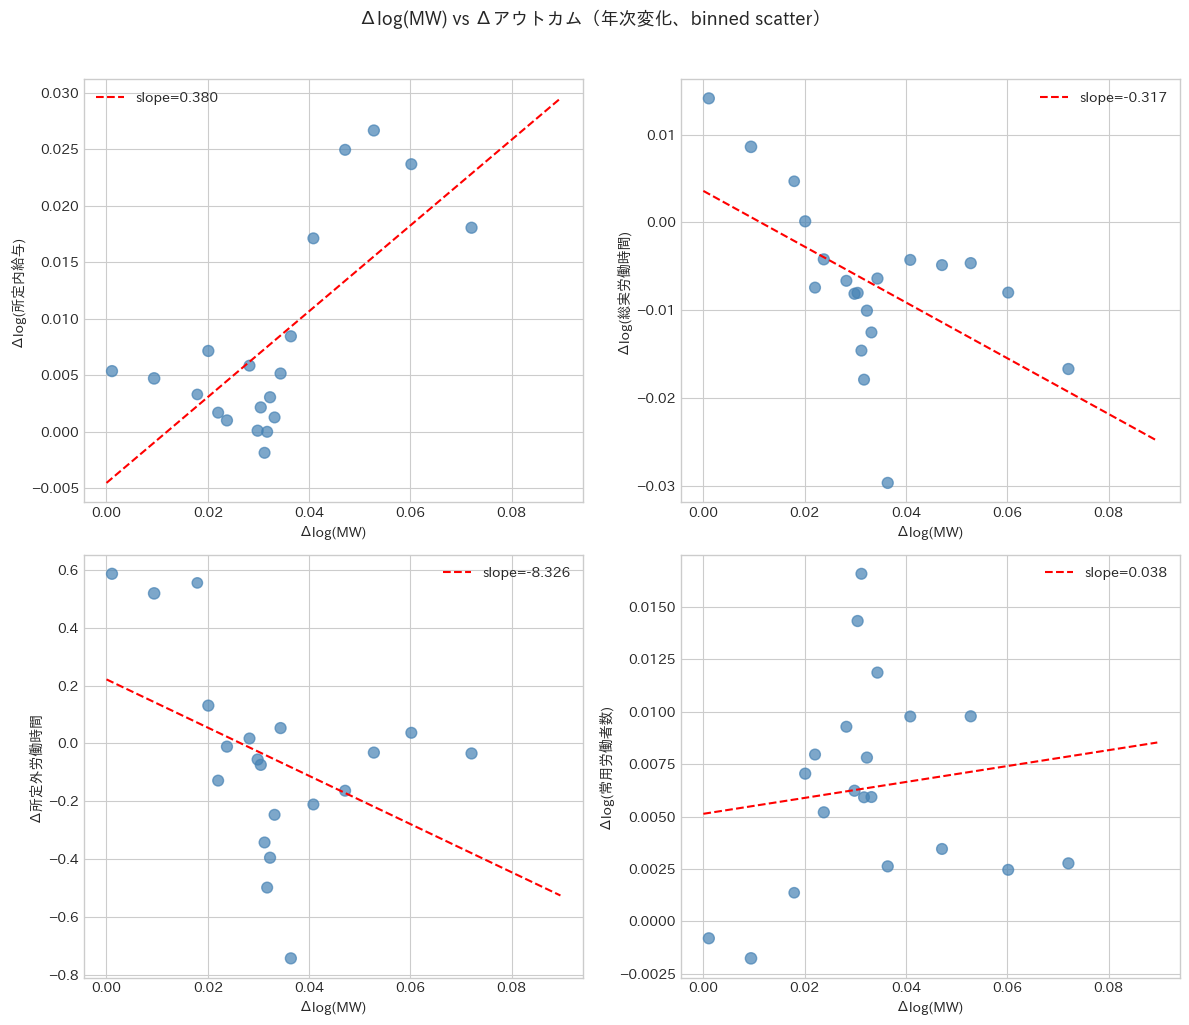

In [11]:
# Binned scatter: Δlog(MW) vs Δlog(アウトカム)
ann = annual.copy()
for col in ['log_wage_scheduled', 'log_hours_total', 'hours_overtime', 'log_workers']:
    ann[f'd_{col}'] = ann.groupby('pref_code')[col].diff()

ann = ann.dropna(subset=['dlog_mw'])

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
scatter_pairs = [
    ('dlog_mw', 'd_log_wage_scheduled', 'Δlog(MW)', 'Δlog(所定内給与)'),
    ('dlog_mw', 'd_log_hours_total', 'Δlog(MW)', 'Δlog(総実労働時間)'),
    ('dlog_mw', 'd_hours_overtime', 'Δlog(MW)', 'Δ所定外労働時間'),
    ('dlog_mw', 'd_log_workers', 'Δlog(MW)', 'Δlog(常用労働者数)'),
]

for ax, (xvar, yvar, xlabel, ylabel) in zip(axes.flat, scatter_pairs):
    valid = ann.dropna(subset=[xvar, yvar])
    # binned scatter (20 bins)
    valid['xbin'] = pd.qcut(valid[xvar], 20, duplicates='drop')
    binned = valid.groupby('xbin', observed=True).agg(
        x=(xvar, 'mean'), y=(yvar, 'mean'), n=(yvar, 'count')
    )
    ax.scatter(binned['x'], binned['y'], s=binned['n']*2, color='steelblue', alpha=0.7)
    # OLS fit line
    coef = np.polyfit(valid[xvar], valid[yvar], 1)
    xline = np.linspace(valid[xvar].min(), valid[xvar].max(), 100)
    ax.plot(xline, np.polyval(coef, xline), 'r--', linewidth=1.5,
            label=f'slope={coef[0]:.3f}')
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.legend()

plt.suptitle('Δlog(MW) vs Δアウトカム（年次変化、binned scatter）', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(OUT / '01_binscatter_dose_outcome.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. まとめ

In [12]:
print('=== 記述統計まとめ ===')
print()
print('生成ファイル:')
print('  data/annual_panel.csv — MW年度ベースの年次パネル（dcDH推定用）')
print()
import os
figs = sorted(os.listdir('../output/figures'))
print(f'  output/figures/ — {len(figs)} 枚:')
for f in figs:
    print(f'    {f}')

=== 記述統計まとめ ===

生成ファイル:
  data/annual_panel.csv — MW年度ベースの年次パネル（dcDH推定用）

  output/figures/ — 8 枚:
    binscatter_dose_outcome.png
    dose_distribution.png
    mw_dispersion.png
    mw_timeseries.png
    outcome_timeseries.png
    outlier_boxplots.png
    parallel_trends_visual.png
    seasonality.png
